In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv(r"/content/House_Rent_Dataset.csv")

In [3]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [4]:


columns_explanation = pd.DataFrame({
    "Column": [
        "Posted On",
        "BHK",
        "Rent",
        "Size",
        "Floor",
        "Area Type",
        "Area Locality",
        "City",
        "Furnishing Status",
        "Tenant Preferred",
        "Bathroom",
        "Point of Contact"
    ],
    "Explanation": [
        "تاريخ نشر الإعلان",
        "عدد غرف النوم",
        "قيمة الإيجار",
        "مساحة العقار",
        "رقم الطابق",
        "نوع المساحة أو المنطقة",
        "اسم المنطقة المحلية",
        "المدينة",
        "حالة الأثاث",
        "نوع المستأجر المفضل",
        "عدد الحمامات",
        "بيانات أو وسيلة التواصل"
    ]
})

columns_explanation


,Column,Explanation
0,Posted On,تاريخ نشر الإعلان
1,BHK,عدد غرف النوم
2,Rent,قيمة الإيجار
3,Size,مساحة العقار
4,Floor,رقم الطابق
5,Area Type,نوع المساحة أو المنطقة
6,Area Locality,اسم المنطقة المحلية
7,City,المدينة
8,Furnishing Status,حالة الأثاث
9,Tenant Preferred,نوع المستأجر المفضل


In [5]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [6]:
df.shape

(4746, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [8]:
df.drop('Posted On',axis=1,inplace=True)

In [9]:
info=pd.DataFrame(df.isnull().sum(),columns=['isnull'])
info.insert(1,'duplicated',df.duplicated().sum(),True)
info.insert(2,'unique',df.nunique(),True)
info.T

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
isnull,0,5,8,0,7,0,0,0,0,4,0
duplicated,8,8,8,8,8,8,8,8,8,8,8
unique,6,243,615,480,3,2235,6,3,3,8,3


(array([1, 2, 3, 4]),
 [Text(1, 0, 'BHK'),
  Text(2, 0, 'Rent'),
  Text(3, 0, 'Size'),
  Text(4, 0, 'Bathroom')])

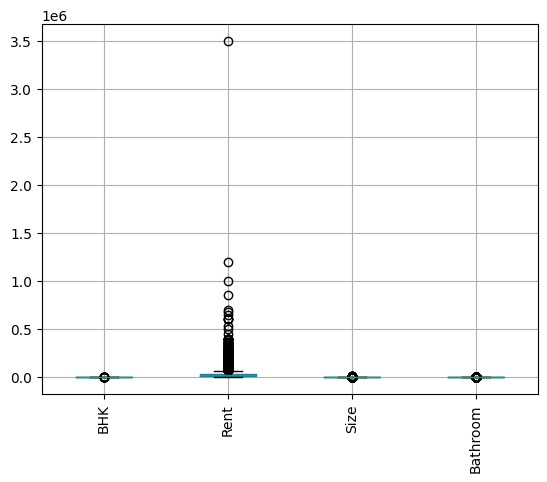

In [10]:
df.boxplot()
plt.xticks(rotation=90)


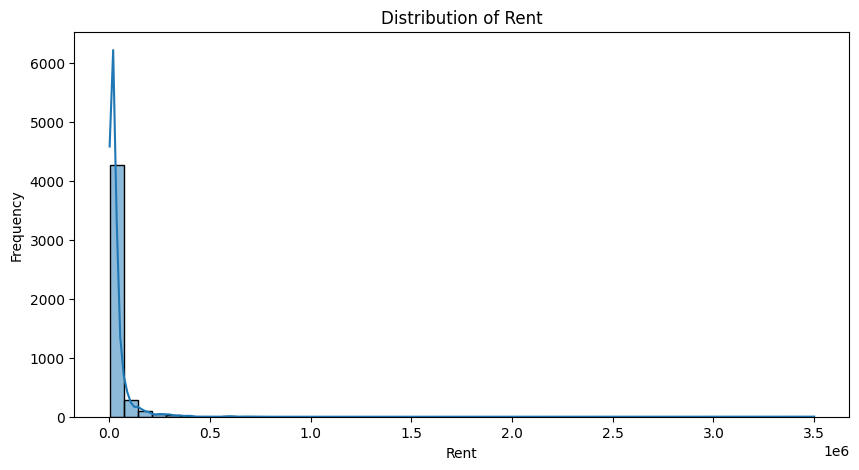

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Rent', bins=50, kde=True)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

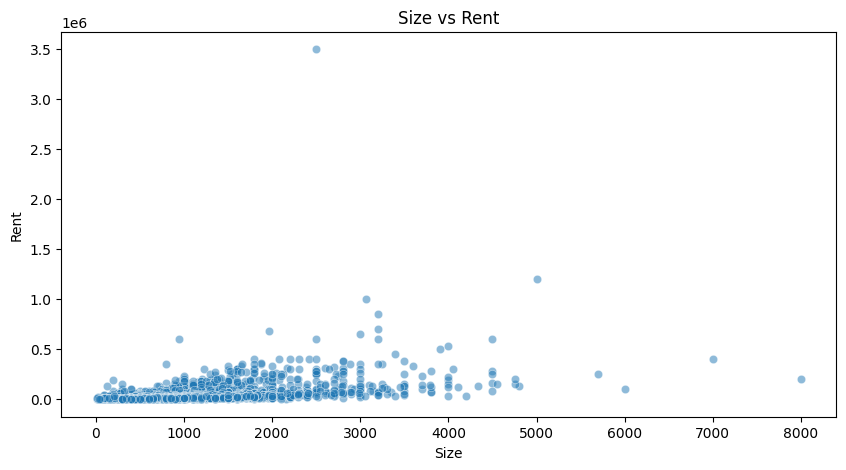

In [12]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Size', y='Rent', alpha=0.5)
plt.title('Size vs Rent')
plt.xlabel('Size')
plt.ylabel('Rent')
plt.show()

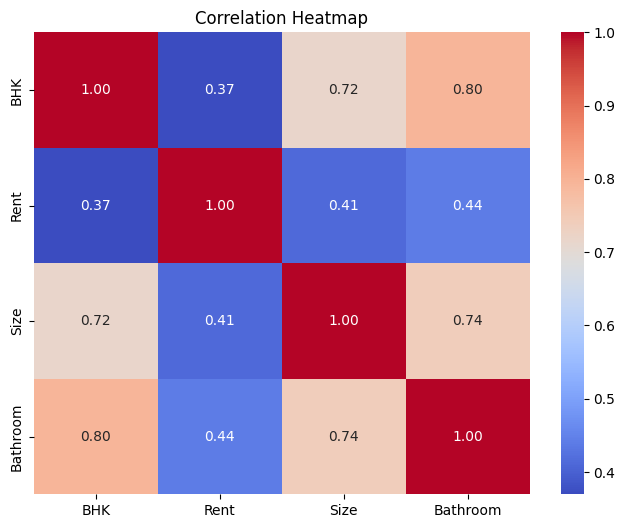

In [13]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

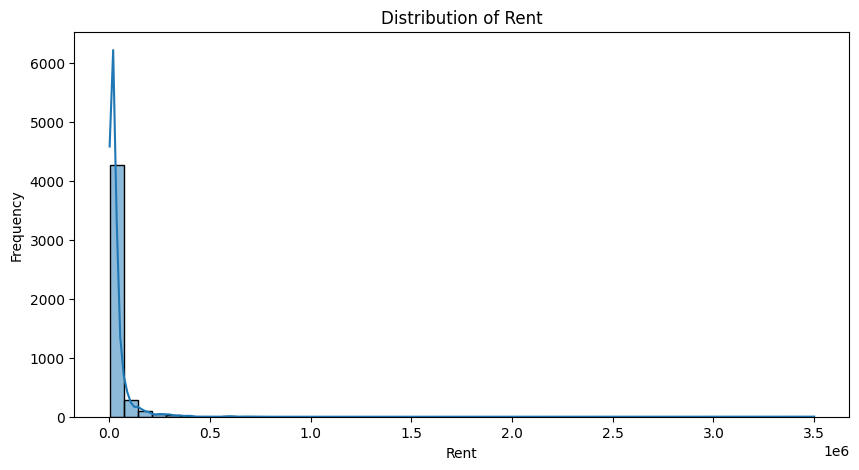

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Rent', bins=50, kde=True)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

In [15]:
list1=df.select_dtypes('number').columns
list2=df.select_dtypes('object').columns

In [16]:
df = df.dropna(subset=['Rent'])

In [17]:
df.shape

(4741, 11)

In [18]:
for i in list1:
    Q1=df[i].quantile(.25)
    Q3=df[i].quantile(.75)
    IQR=Q3-Q1
    upper=Q3+(1.5*IQR)
    lower=Q1-(1.5*IQR)
    df[i] = df[i].clip(lower, upper)



In [19]:
for i in list2:
    print(i,df[i].nunique())

Floor 480
Area Type 3
Area Locality 2234
City 6
Furnishing Status 3
Tenant Preferred 3
Point of Contact 3


In [20]:
df = pd.get_dummies(df, columns=['Area Type','City','Furnishing Status','Tenant Preferred','Point of Contact'], drop_first=True)

In [21]:
parts = df["Floor"].str.split(" out of ", expand=True)
parts[0].unique()

array(['Ground', '1', '2', '4', '3', '5', '7', '8', 'Upper Basement',
       '11', 'Lower Basement', '6', '14', '43', '13', '18', '17', '9',
       '19', '60', '34', '12', '26', '25', '53', '16', '10', '39', '32',
       '47', '28', '20', '15', '65', '40', '37', '22', '21', '30', '35',
       '33', '44', '41', '46', '27', '45', '48', '50', '24', '23', '29',
       '49', '36', '76'], dtype=object)

In [22]:
df["Floor_Num"] = parts[0].replace({"Ground": 0, "Upper Basement": -1, "Lower Basement": -2}).astype(float)
df["Total_Floors"] = pd.to_numeric(parts[1])
df = df.drop(columns="Floor")

In [23]:
x=df.drop('Rent',axis=1)
y=df['Rent']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42,shuffle=True)

In [24]:
x_train = x_train.dropna()
y_train = y_train.loc[x_train.index]

x_test = x_test.dropna()
y_test = y_test.loc[x_test.index]

In [25]:
print(x_train.isna().sum().sum())
print(x_test.isna().sum().sum())


0
0


In [26]:
x_train = x_train.drop_duplicates()
y_train = y_train.loc[x_train.index]

x_test = x_test.drop_duplicates()
y_test = y_test.loc[x_test.index]

In [27]:
print(x_train.duplicated().sum())
print(x_test.duplicated().sum())

0
0


In [28]:
print(y.isna().sum())

0


In [29]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

x_train[['Area Locality']] = encoder.fit_transform(x_train[['Area Locality']])

x_test[['Area Locality']] = encoder.transform(x_test[['Area Locality']])

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train['Size'] = scaler.fit_transform(x_train[['Size']])
x_test['Size'] = scaler.transform(x_test[['Size']])

In [31]:
from sklearn.linear_model import LinearRegression
model=LinearRegression(
    fit_intercept=True
    ,copy_X=True,
    n_jobs=None,
    positive=False
)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_pred))

6898.878158836938
93384790.01674451
0.7669982154461836


In [33]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 37.9 MB/s  0:00:02


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [35]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [36]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

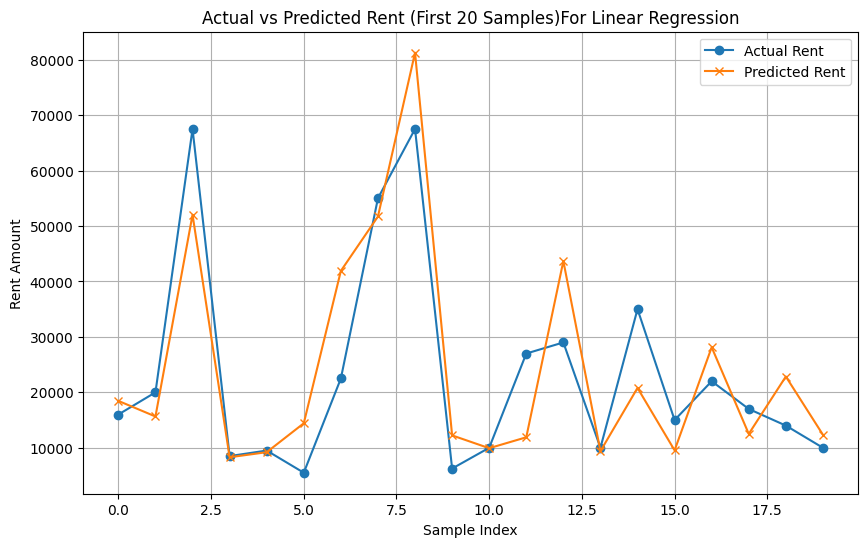

  7%|▋         | 1/15 [00:00<00:04,  3.36it/s]

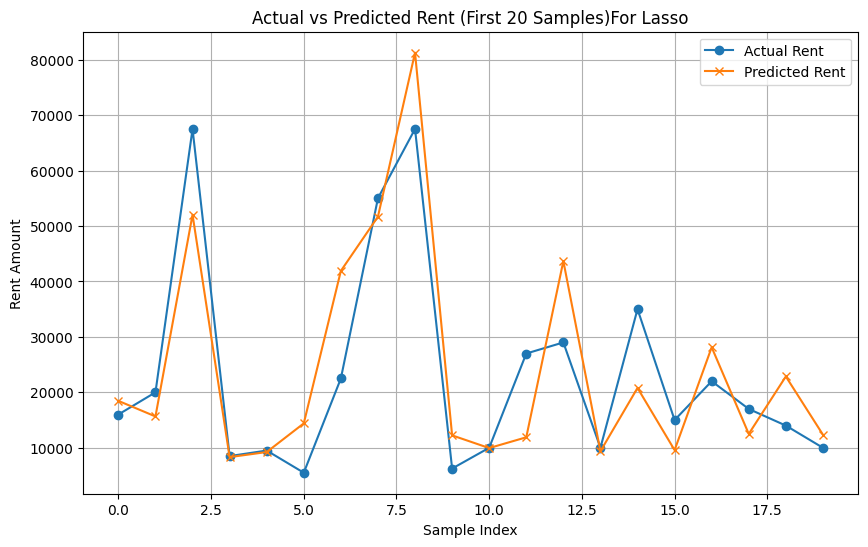

 13%|█▎        | 2/15 [00:00<00:04,  2.75it/s]

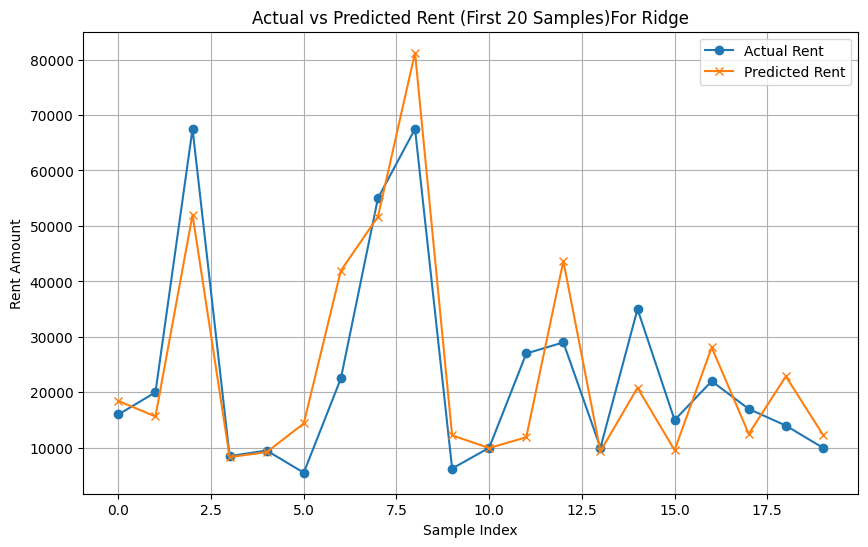

 20%|██        | 3/15 [00:01<00:04,  2.63it/s]

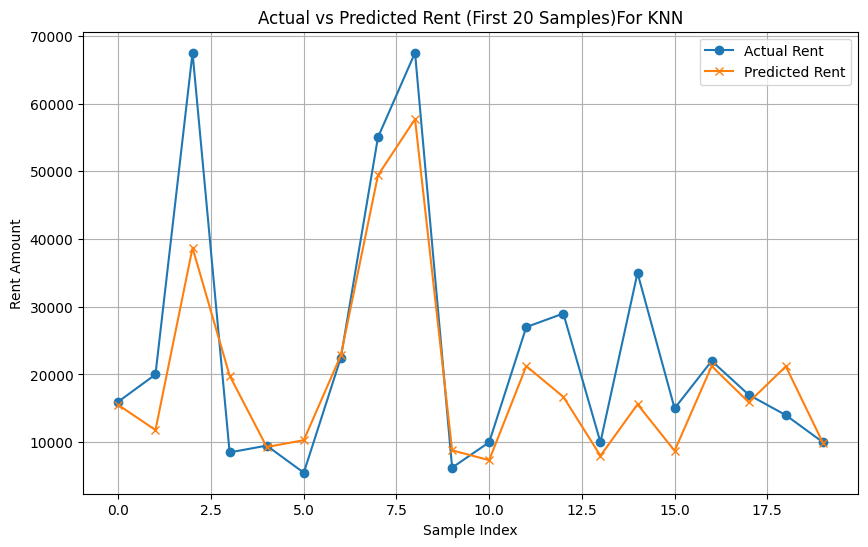

 27%|██▋       | 4/15 [00:02<00:07,  1.50it/s]

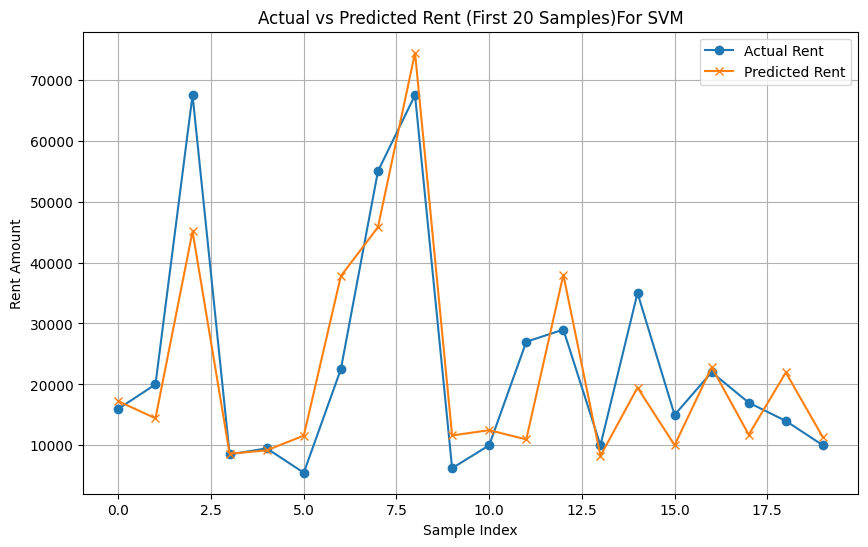

 33%|███▎      | 5/15 [01:34<05:37, 33.79s/it]

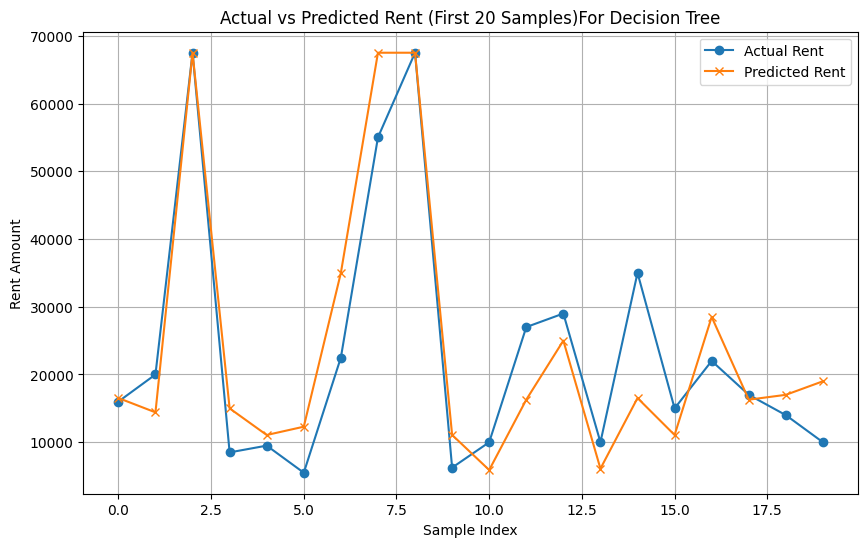

 40%|████      | 6/15 [01:34<03:21, 22.38s/it]

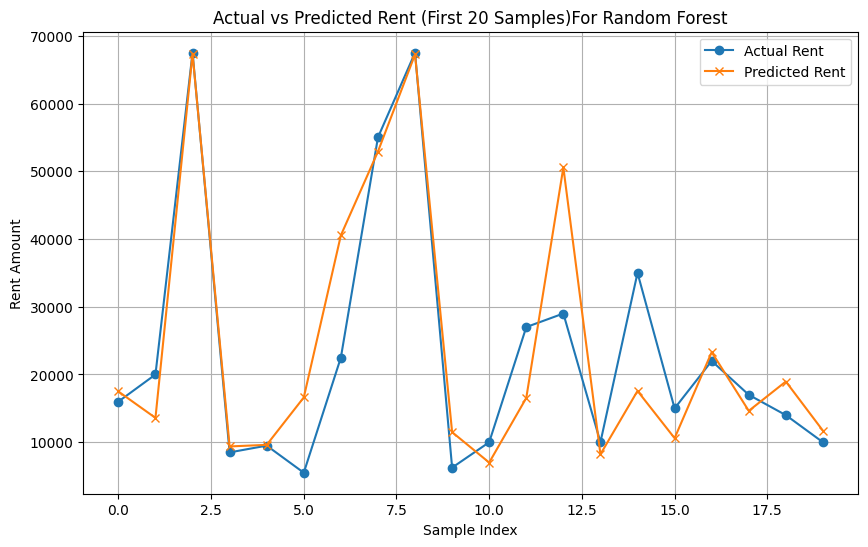

 47%|████▋     | 7/15 [01:35<02:02, 15.33s/it]

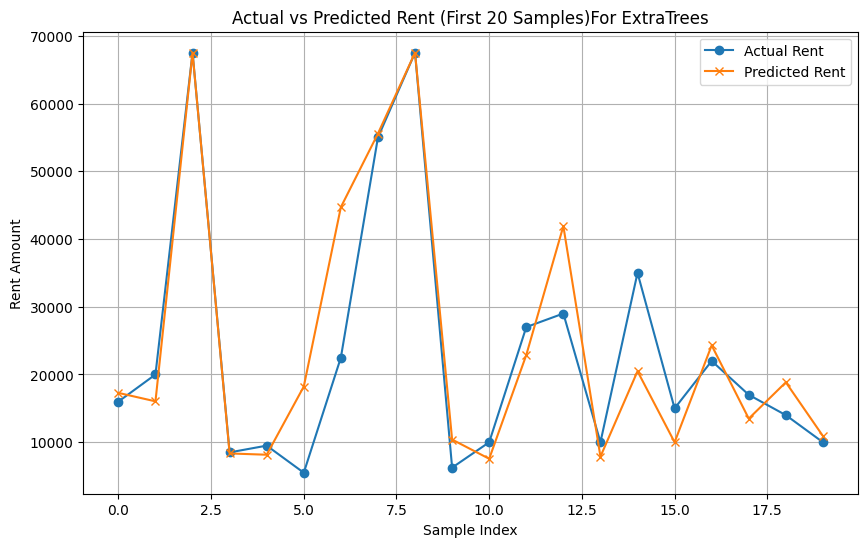

 53%|█████▎    | 8/15 [01:37<01:17, 11.01s/it]

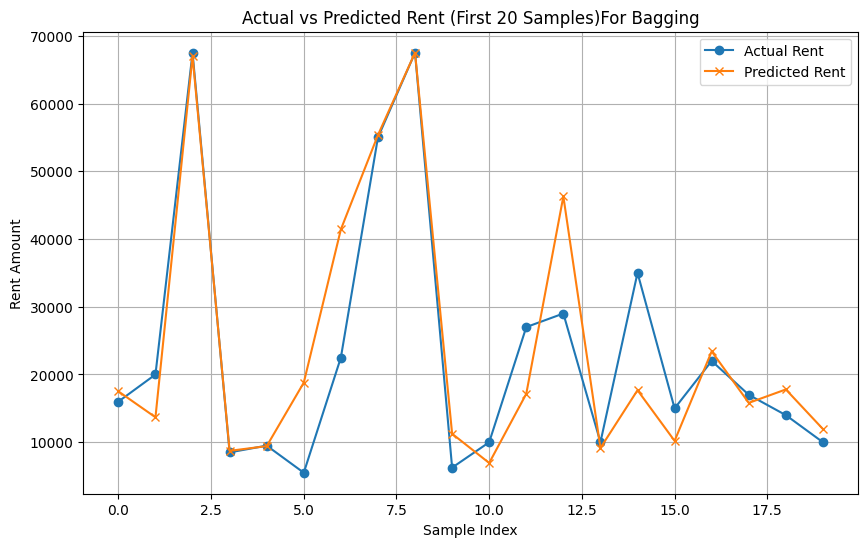

 60%|██████    | 9/15 [01:38<00:47,  7.85s/it]

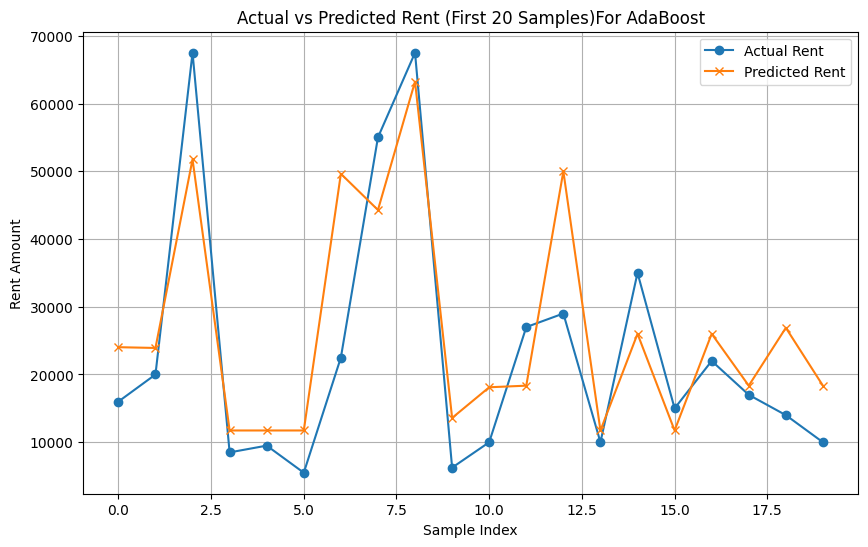

 67%|██████▋   | 10/15 [01:38<00:27,  5.53s/it]

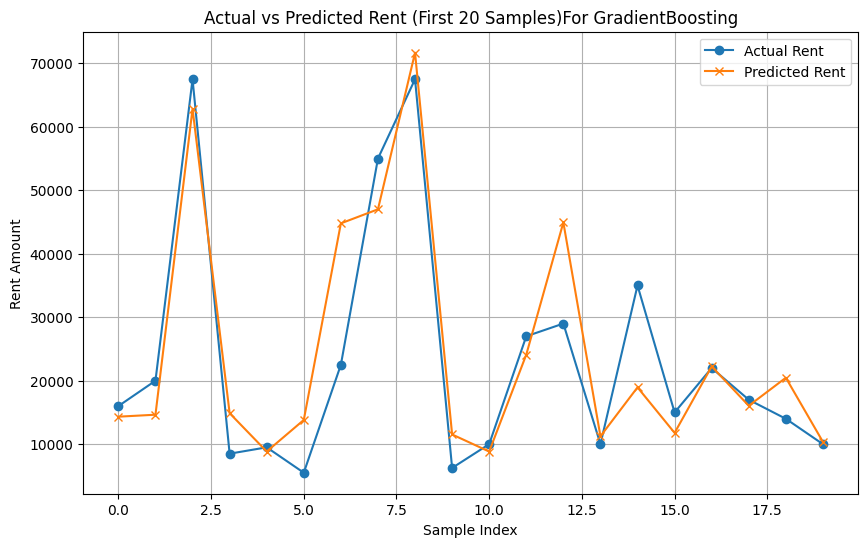

 73%|███████▎  | 11/15 [01:39<00:16,  4.07s/it]

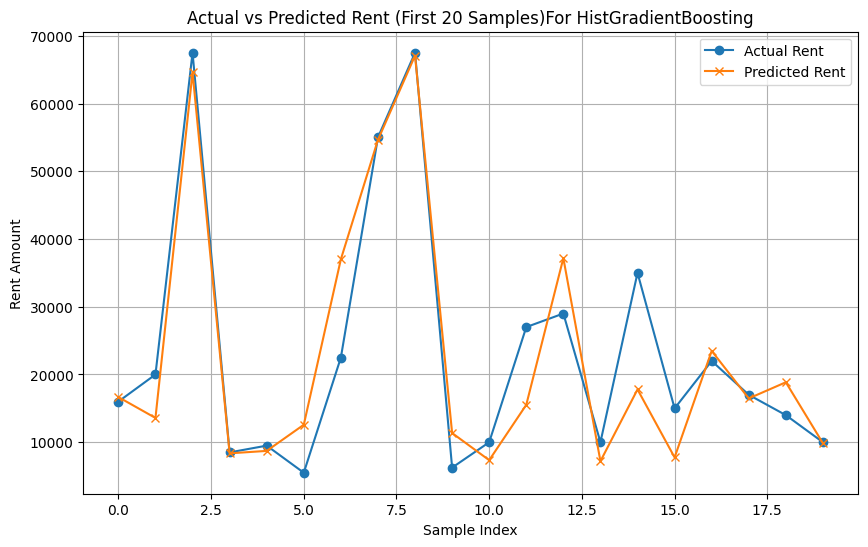

 80%|████████  | 12/15 [01:40<00:09,  3.06s/it]

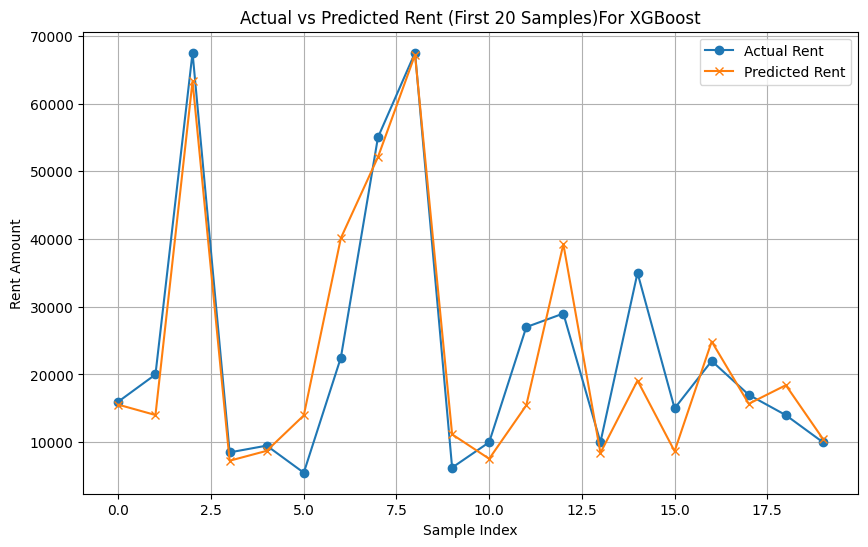

 87%|████████▋ | 13/15 [01:40<00:04,  2.26s/it]

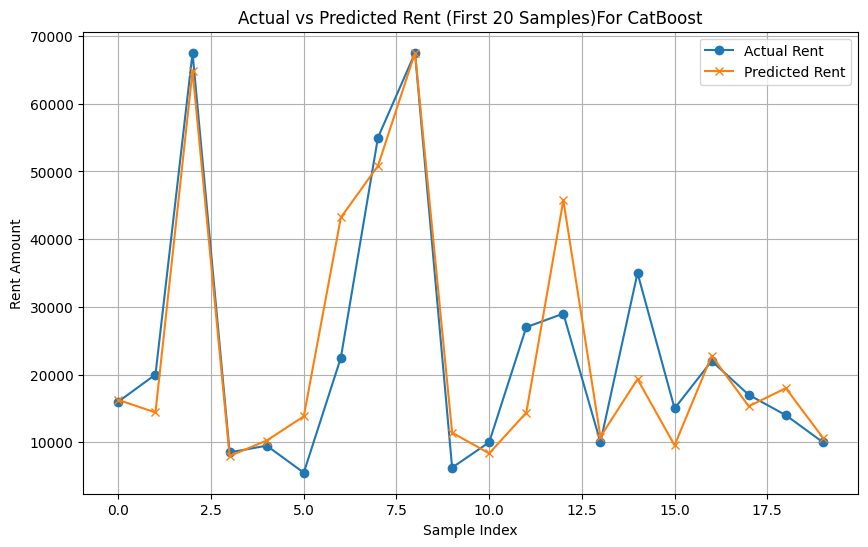

 93%|█████████▎| 14/15 [01:41<00:01,  1.71s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001583 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 630
[LightGBM] [Info] Number of data points in the train set: 3768, number of used features: 18
[LightGBM] [Info] Start training from score 24646.089437


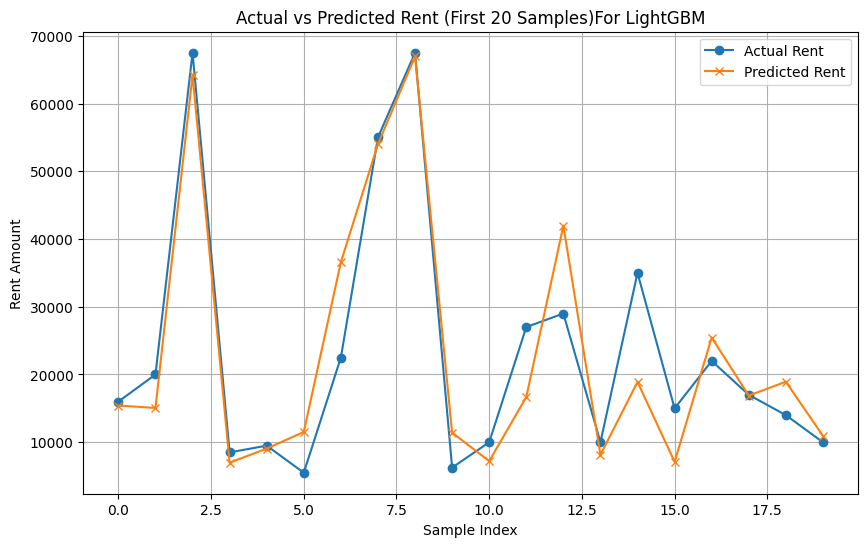

100%|██████████| 15/15 [01:41<00:00,  6.78s/it]


In [37]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(x_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [38]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(x_train, y_train)
model2.fit(x_train, y_train)
model3.fit(x_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, x_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, x_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, x_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [39]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(x_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, x_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [40]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [41]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
LightGBM,3728.603934,5186.500142,2.966554e+07,6.962829e+07,5446.608289,8344.356759,0.925311,0.826272
CatBoost,4662.412163,5201.028827,4.737583e+07,7.013237e+07,6883.010487,8374.507111,0.880721,0.825015
HistGradientBoosting,3754.066159,5253.398734,2.975216e+07,7.089443e+07,5454.554125,8419.882757,0.925093,0.823113
XGBoost,3177.442922,5248.712225,2.093203e+07,7.173345e+07,4575.153188,8469.560416,0.947299,0.821020
ExtraTrees,1.130573,5355.532460,9.647028e+01,7.381122e+07,9.821928,8591.345909,1.000000,0.815836
Bagging,3423.668637,5584.779262,2.322314e+07,7.417897e+07,4819.039723,8612.721143,0.941531,0.814918
Simple Voting,2802.553862,5186.500142,1.510934e+07,6.962829e+07,3887.072835,8344.356759,0.961959,0.810463
Voting,2802.553862,5186.500142,1.510934e+07,6.962829e+07,3887.072835,8344.356759,0.961959,0.810463
Random Forest,3426.302581,5567.230840,2.311175e+07,7.660109e+07,4807.467642,8752.204724,0.941811,0.808875
Weighted Voting,3035.485550,5186.500142,1.726752e+07,6.962829e+07,4155.419985,8344.356759,0.956525,0.804720


<Axes: >

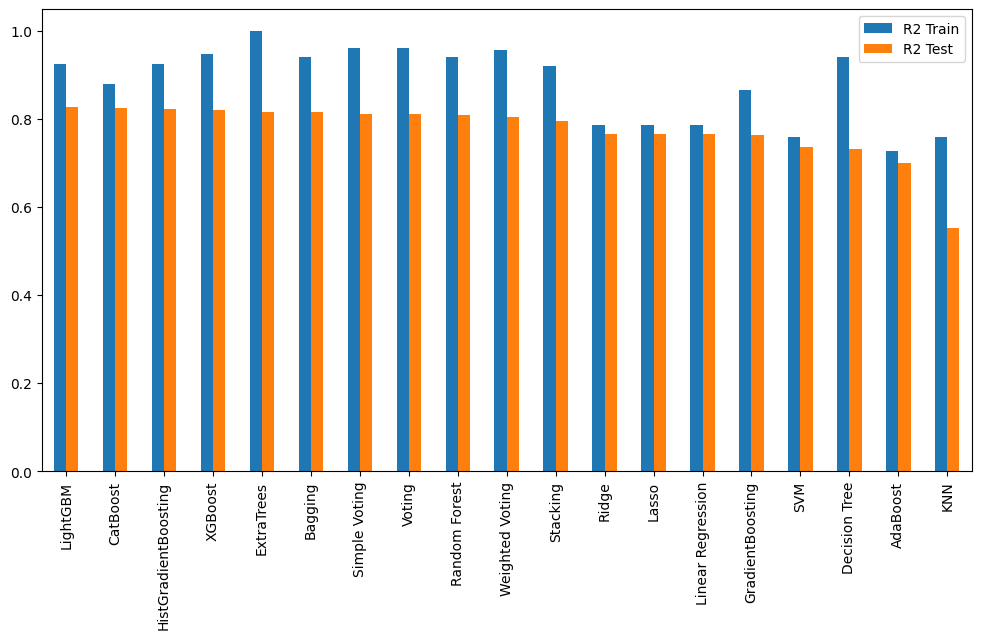

In [42]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

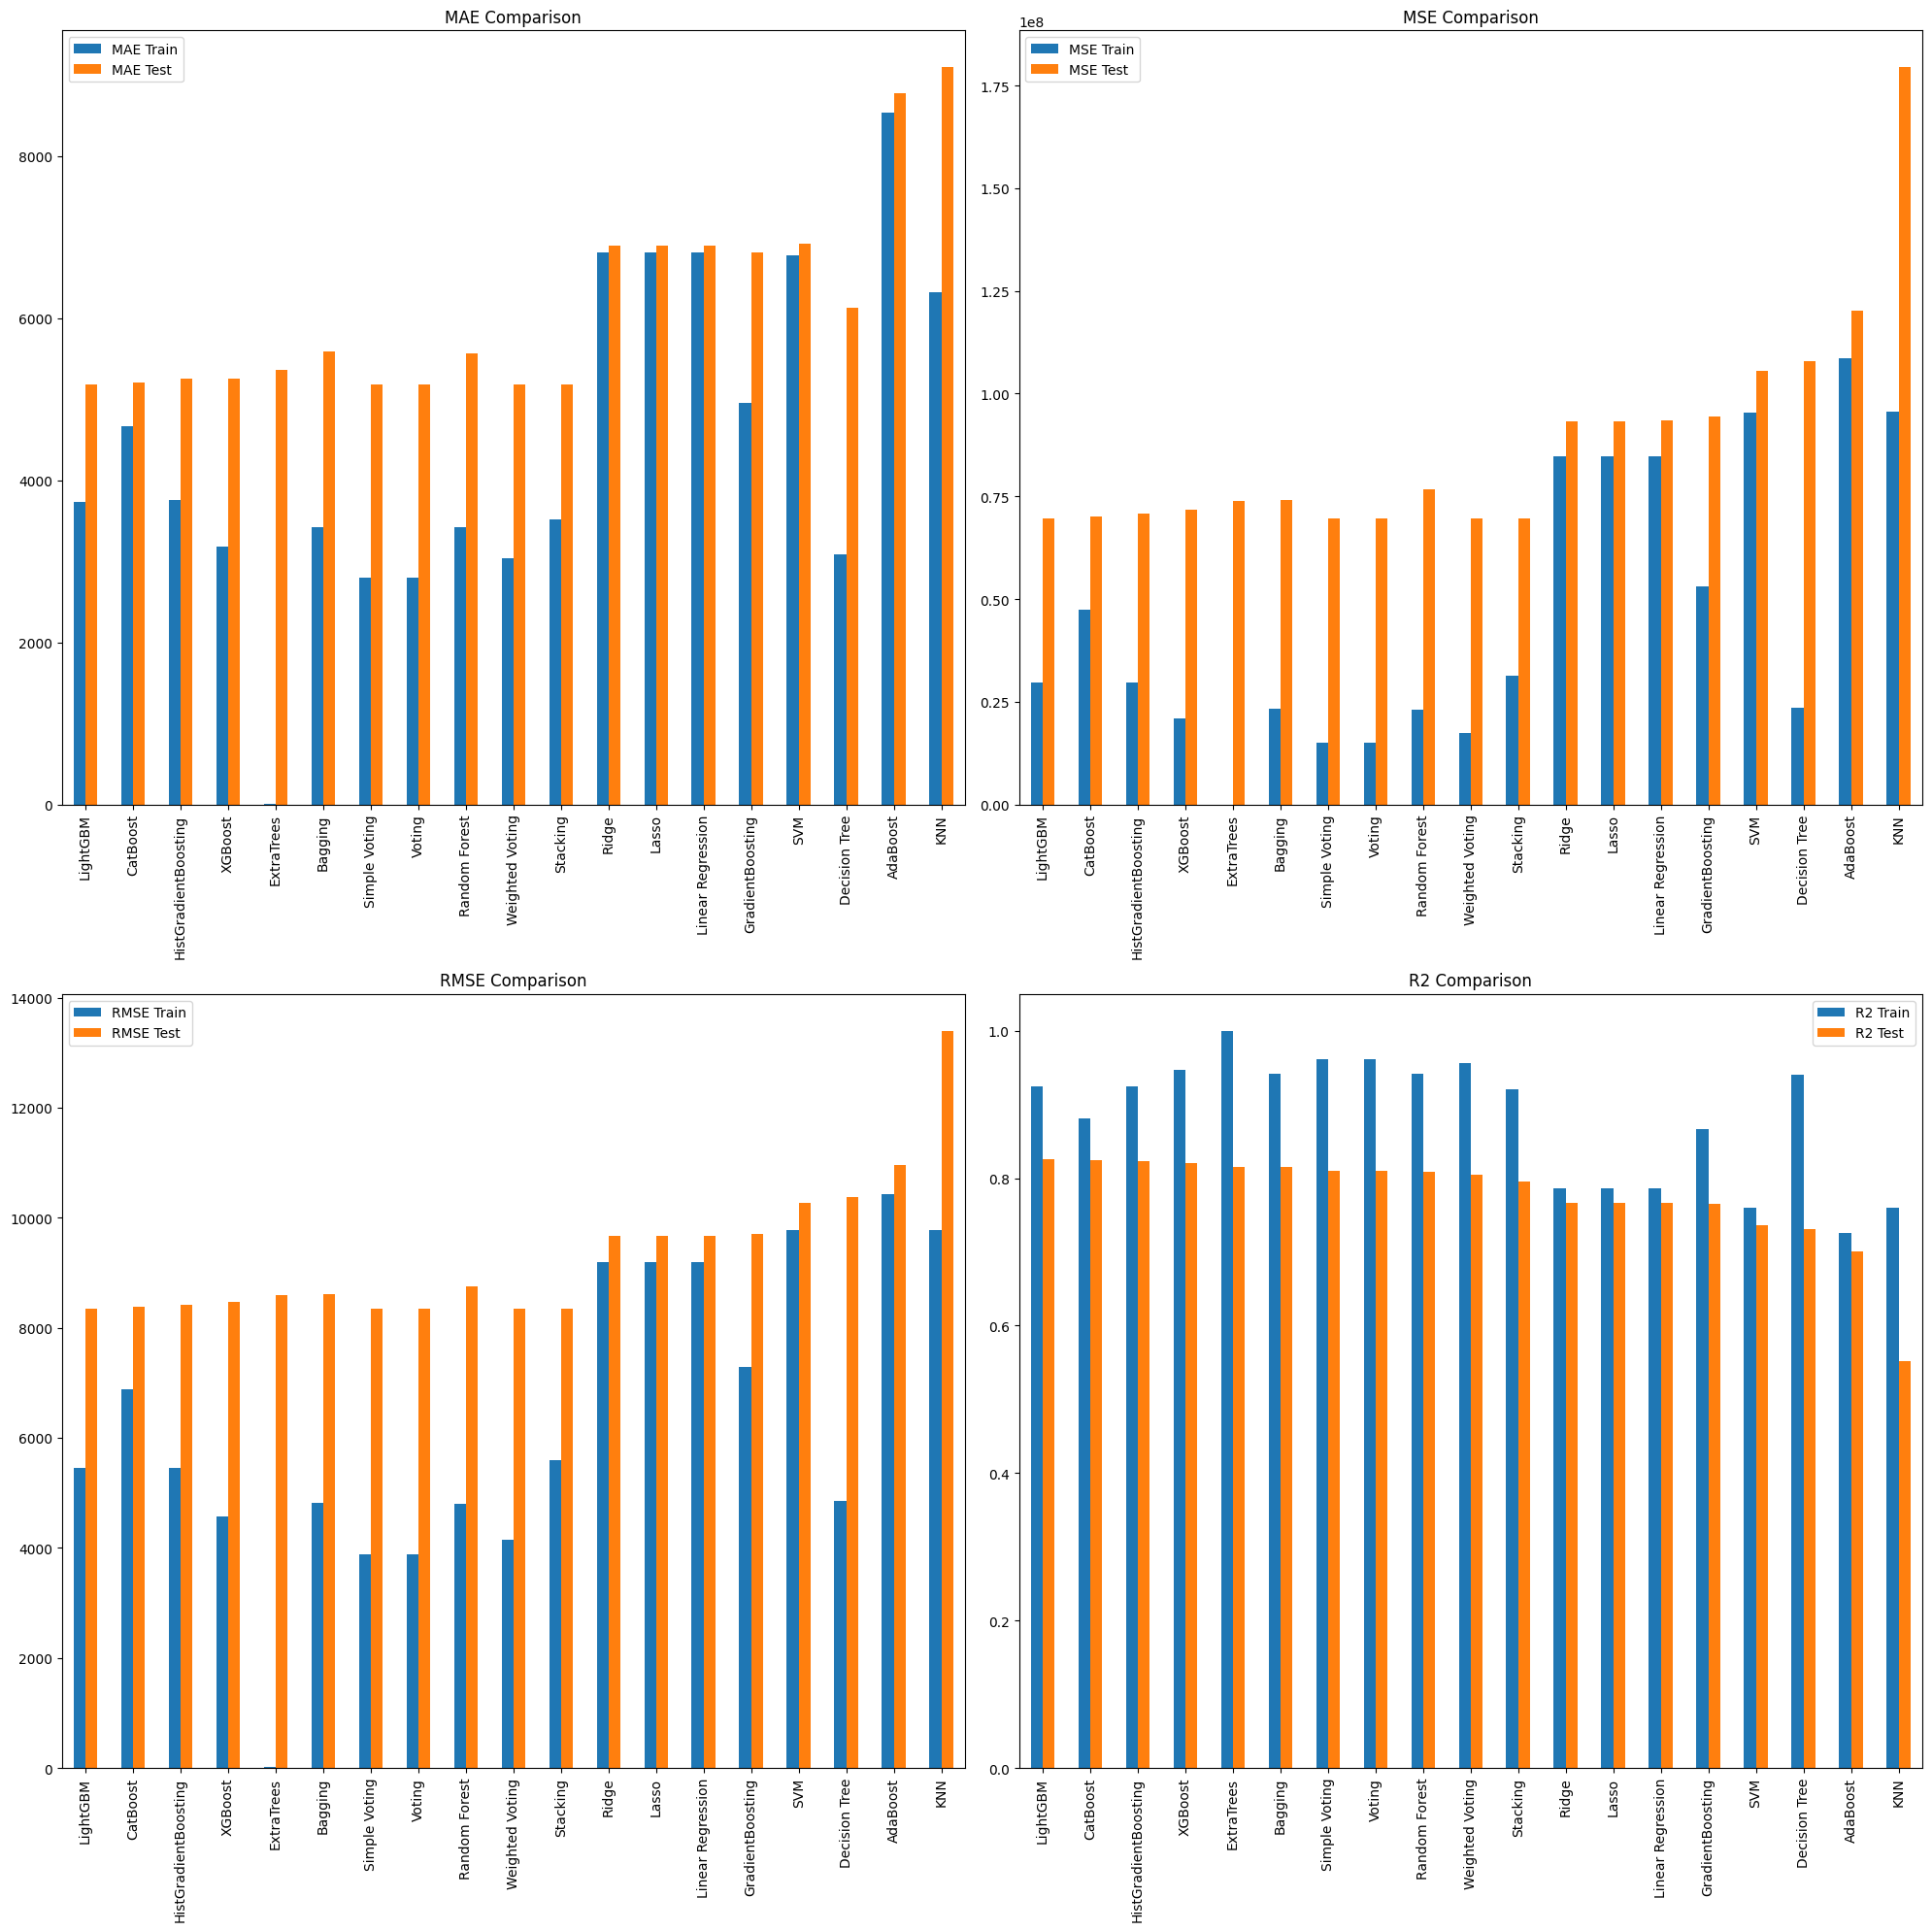

In [43]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [44]:
from sklearn.decomposition import PCA

print(x_train.shape)

pca = PCA(n_components=3,random_state=42)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)
print(x_test_pca.shape)

(3768, 19)
(947, 3)


<Figure size 1000x600 with 0 Axes>

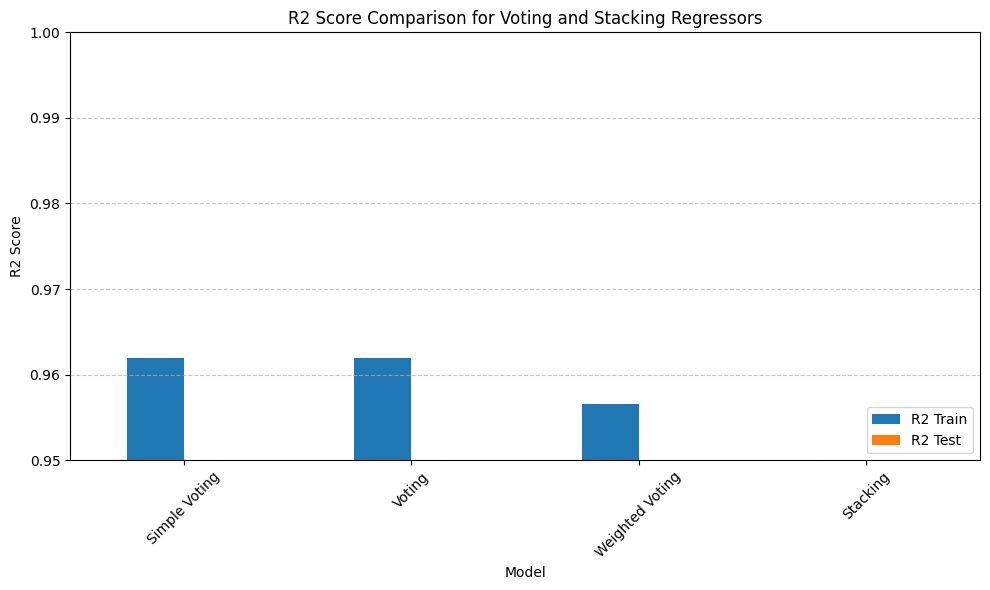

In [45]:

ensemble_models = ["Voting", "Simple Voting", "Weighted Voting", "Stacking"]
filtered_errors = errors_df.loc[errors_df.index.isin(ensemble_models)]

plt.figure(figsize=(10, 6))
filtered_errors[["R2 Train", "R2 Test"]].plot.bar(figsize=(10, 6))
plt.title("R2 Score Comparison for Voting and Stacking Regressors")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.ylim(0.95, 1.0)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()